# 05 · Saati ne kurar: para mı, okul mu?

**Soru:** Ülkeler doğurganlık düşüşünün dönüm noktasına (t0) geldiklerinde **gelirleri** mi birbirine benziyor, yoksa **genç kadınların eğitim düzeyi** mi?

**Bu notebook ne yapıyor?**
1. 04'te bulduğumuz dönüm noktası yıllarını (`clean/t0_tablosu.csv`) alıyor.
2. Her ülkenin o yıldaki gelirini ve genç kadın eğitimini dış veriden okuyor.
3. İki testle "hangisi daha tutarlı bir işaret?" sorusuna bakıyor.

**Önemli:** Bu bir neden-sonuç analizi değil. "Eğitim doğurganlığı düşürür" demiyoruz. Sadece "düşüş başladığında ülkeler nasıl bir durumdaydı?" diye bakıyoruz. Ayrıca sonuç ülkeler hakkında, bireyler hakkında değil.

## 1. Veri

| Veri | Kaynak | Ne ölçüyor? |
|---|---|---|
| `t0_tablosu.csv` | Bizim 04 notebook'umuz (UN WPP 2024) | Her ülkenin dönüm noktası yılı |
| Gelir | Maddison Project 2023 | Kişi başı gelir (2011 dolar, ülkeler arası fiyat farkına göre düzeltilmiş) |
| Eğitim | Barro–Lee | 25–34 yaş kadınların ortalama okul yılı (5 yılda bir) |

Kaynakların tam listesi ve atıfları: `data_dis/KAYNAKLAR.md`.

`yillik()` fonksiyonu, 5 yılda bir ölçülen değerlerin arasını doldurur (interpolasyon). Logaritma üzerinden yapıyoruz, çünkü gelir ve eğitim yüzde olarak büyür.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon

t0 = pd.read_csv("../clean/t0_tablosu.csv")
gelir = pd.read_csv("../data_dis/gdp-per-capita-maddison-project-database.csv")
gelir = gelir.rename(columns={"code": "ISO3_code", "gdp_per_capita": "deger"})[["ISO3_code", "year", "deger"]]
egitim = pd.read_csv("../data_dis/barrolee_BL_v3_F2534.csv")
egitim = egitim.rename(columns={"WBcode": "ISO3_code", "yr_sch": "deger"})[["ISO3_code", "year", "deger"]]

def yillik(veri):
    """Her ülke için 1950–2015 arası yıllık log değer tablosu (satır: yıl, sütun: ülke kodu)."""
    veri = veri[veri["ISO3_code"].isin(t0["ISO3_code"]) & (veri["deger"] > 0)]
    sonuc = {}
    for kod, d in veri.groupby("ISO3_code"):
        d = d.sort_values("year")
        yillar = np.arange(d["year"].min(), d["year"].max() + 1)
        sonuc[kod] = pd.Series(np.interp(yillar, d["year"], np.log(d["deger"])), index=yillar)
    return pd.DataFrame(sonuc).loc[1950:2015]

G, E = yillik(gelir), yillik(egitim)
print("Gelir verisi olan ülke:", G.shape[1], "| Eğitim verisi olan ülke:", E.shape[1], "(200 ülkeden)")

Gelir verisi olan ülke: 164 | Eğitim verisi olan ülke: 144 (200 ülkeden)


## 2. Örneklem: hangi ülkeler analize giriyor?

Üç koşul var:
1. **Dönüm noktası güvenilir** (04, 8. bölüm): düşüşün iki yanı da veride görülüyor.
2. **t0, 1952–2013 arasında:** eğitim verisi 1950–2015 arasını kapsıyor.
3. **İki dış veride de ülke var.**

Dışarıda kalan ülkeleri **gizlemiyoruz**, listeliyoruz (etik).

In [2]:
orn = t0[t0["guvenilir"] & t0["t0"].between(1952, 2013)].copy()
orn["yil"] = orn["t0"].round().astype(int)

def deger_al(P, kod, yil):
    if kod in P.columns and not np.isnan(P.at[yil, kod]):
        return P.at[yil, kod]
    return np.nan

orn["log_gelir"] = [deger_al(G, k, y) for k, y in zip(orn["ISO3_code"], orn["yil"])]
orn["log_egitim"] = [deger_al(E, k, y) for k, y in zip(orn["ISO3_code"], orn["yil"])]

disarida = orn[orn["log_gelir"].isna() | orn["log_egitim"].isna()]
orn = orn.dropna(subset=["log_gelir", "log_egitim"])
orn["gelir"] = np.exp(orn["log_gelir"]).round(0)
orn["egitim"] = np.exp(orn["log_egitim"]).round(2)

print("Koşul 1 + 2'yi sağlayan:", len(orn) + len(disarida), "ülke")
print("Dış veri eksik olduğu için çıkan:", len(disarida), "→", ", ".join(disarida["Location"]))
print("\nANALİZ:", len(orn), "ülke")
print(orn["bolge"].value_counts())

Koşul 1 + 2'yi sağlayan: 112 ülke
Dış veri eksik olduğu için çıkan: 46 → Azerbaijan, Bahamas, Armenia, Bhutan, Bosnia and Herzegovina, Belize, Solomon Islands, Brunei Darussalam, Cabo Verde, Eritrea, Fiji, French Guiana, French Polynesia, Djibouti, State of Palestine, Kiribati, Grenada, Guadeloupe, Guam, Guyana, Dem. People's Republic of Korea, Kosovo (under UNSC res. 1244), Lebanon, China, Macao SAR, Maldives, Martinique, Oman, Curaçao, Aruba, New Caledonia, Vanuatu, Micronesia (Fed. States of), Papua New Guinea, Timor-Leste, Puerto Rico, Réunion, Saint Lucia, Saint Vincent and the Grenadines, Sao Tome and Principe, Seychelles, Western Sahara, Suriname, Tonga, Turkmenistan, North Macedonia, Uzbekistan

ANALİZ: 66 ülke
bolge
Asia                               31
Latin America and the Caribbean    19
Africa                             15
Europe                              1
Name: count, dtype: int64


**Dürüst not:** Avrupa ve Kuzey Amerika neredeyse hiç yok, çünkü düşüşleri 1950'den önce oldu (04'te güvenilir değil). Dış veri eksikleri ise çoğunlukla küçük ada ülkeleri. Yani sonuç **1950 sonrası dönüşen ülkeler** için geçerli. Bunu sunumda söyleyeceğiz.

## 3. İlk bakış: dönüm noktasında ülkeler

Medyan: ülkelerin yarısı bunun altında, yarısı üstünde.

In [3]:
vitrin = ["Bangladesh", "India", "Türkiye", "Republic of Korea", "Iran (Islamic Republic of)",
          "Brazil", "Mexico", "Egypt", "Indonesia", "Saudi Arabia"]
print(f"Medyan gelir: {orn['gelir'].median():,.0f} $ | Medyan genç kadın eğitimi: {orn['egitim'].median():.1f} yıl\n")
print("En yoksul:", orn.loc[orn["gelir"].idxmin(), "Location"], f"{orn['gelir'].min():,.0f} $")
print("En zengin:", orn.loc[orn["gelir"].idxmax(), "Location"], f"{orn['gelir'].max():,.0f} $")
print(f"→ {orn['gelir'].max() / orn['gelir'].min():.0f} kat fark\n")
orn.set_index("Location").loc[vitrin, ["yil", "gelir", "egitim"]].sort_values("gelir")

Medyan gelir: 4,909 $ | Medyan genç kadın eğitimi: 5.5 yıl

En yoksul: Bangladesh 1,096 $
En zengin: Saudi Arabia 24,054 $
→ 22 kat fark



,yil,gelir,egitim
Location,,,
Bangladesh,1993,1096.0,2.80
India,1986,1755.0,2.19
Republic of Korea,1968,2468.0,6.07
Indonesia,1979,2810.0,3.64
Egypt,1994,4747.0,4.83
Türkiye,1982,6381.0,3.59
Iran (Islamic Republic of),1991,6381.0,5.51
Brazil,1976,7079.0,2.43
Mexico,1986,9283.0,6.03


## 4. Test 1: Hangisi daha toplu?

**Dikkat, tuzak:** "Gelir 22 kat, eğitim 7 kat farklı" demek **adil değil**. Eğitim zaten dar bir aralıkta değişir (0–14 yıl), gelir çok geniş bir aralıkta (500–100.000 $).

**Adil karşılaştırma:** Her değişkenin dönüm noktasındaki yayılımını, **aynı yıllarda bütün dünyadaki yayılımına** bölüyoruz.
- Sonuç 1'e yakınsa: Dönüm noktasındaki ülkeler, dünyanın geneli kadar dağınık. Yani eşik yok.
- Sonuç 0'a yakınsa: Dönüm noktasındaki ülkeler çok benzer. Yani güçlü bir eşik var.

**Bootstrap:** Ülkeleri torbadan rastgele, geri koyarak 5.000 kez çekip oranı yeniden hesaplıyoruz. Böylece güven aralığı elde ediyoruz.

In [4]:
dunya_gelir = np.mean([G.loc[y].std() for y in orn["yil"]])     # aynı yıllarda dünyadaki yayılım
dunya_egitim = np.mean([E.loc[y].std() for y in orn["yil"]])

def daralma(o):
    return o["log_gelir"].std() / dunya_gelir, o["log_egitim"].std() / dunya_egitim

dg, de = daralma(orn)
print(f"Gelir:  dönüm noktasındaki yayılım = dünyadaki yayılımın {dg:.2f} katı")
print(f"Eğitim: dönüm noktasındaki yayılım = dünyadaki yayılımın {de:.2f} katı")
print(f"Oran (gelir / eğitim) = {dg / de:.2f}")

rng = np.random.default_rng(2026)
bs = []
for _ in range(5000):
    o = orn.sample(len(orn), replace=True, random_state=rng.integers(1e9))
    a, b = daralma(o)
    bs.append(a / b)
alt, ust = np.percentile(bs, [2.5, 97.5])
print(f"%95 güven aralığı: [{alt:.2f}, {ust:.2f}]  → 1'in üstündeyse eğitim anlamlı derecede daha toplu")

Gelir:  dönüm noktasındaki yayılım = dünyadaki yayılımın 0.64 katı
Eğitim: dönüm noktasındaki yayılım = dünyadaki yayılımın 0.48 katı
Oran (gelir / eğitim) = 1.34


%95 güven aralığı: [1.09, 1.67]  → 1'in üstündeyse eğitim anlamlı derecede daha toplu


## 5. Test 2: Eşiği bilseydik dönüm yılını tahmin edebilir miydik?

Her ülke için şunu yapıyoruz:
1. O ülkeyi **dışarıda bırak**. Diğer ülkelerin dönüm noktasındaki medyan değerini "eşik" say.
2. Bu ülke eşiği hangi yıl geçmiş? Gerçek dönüm noktasından kaç yıl sapıyor?

Üç yöntemi karşılaştırıyoruz:
- **Gelir eşiği**
- **Eğitim eşiği**
- **Takvim (kıyas):** Hiçbir şey bilmeden, diğer ülkelerin medyan dönüm yılını tahmin olarak kullan.

**Wilcoxon testi:** Aynı ülkelerde iki yöntemin hatalarını eşleştirerek karşılaştırır. p küçükse fark tesadüf değil.

In [5]:
def esik_hatasi(P, sutun):
    hatalar = []
    for j, (kod, gercek_t0) in enumerate(zip(orn["ISO3_code"], orn["t0"])):
        esik = np.median(np.delete(orn[sutun].values, j))       # bu ülke hariç
        seri = P[kod].dropna()
        if seri.iloc[0] >= esik or (seri < esik).all():
            hatalar.append(np.nan)                              # eşiği 1950'den önce geçmiş ya da hiç geçmemiş
        else:
            hatalar.append(seri[seri >= esik].index[0] - gercek_t0)
    return np.array(hatalar)

orn["hata_gelir"] = esik_hatasi(G, "log_gelir")
orn["hata_egitim"] = esik_hatasi(E, "log_egitim")
orn["hata_takvim"] = [orn["t0"].drop(i).median() - x for i, x in zip(orn.index, orn["t0"])]

ozet = pd.DataFrame({
    "Tahmin edilebilen ülke": orn[["hata_gelir", "hata_egitim", "hata_takvim"]].notna().sum(),
    "Medyan hata (yıl)": orn[["hata_gelir", "hata_egitim", "hata_takvim"]].abs().median().round(1)})
ozet.index = ["Gelir eşiği", "Eğitim eşiği", "Takvim (kıyas)"]
print(ozet, "\n")

for a, b in [("hata_gelir", "hata_egitim"), ("hata_takvim", "hata_egitim"), ("hata_takvim", "hata_gelir")]:
    d = orn[[a, b]].dropna().abs()
    print(f"{a} vs {b}: {len(d)} ülke, medyanlar {d[a].median():.1f} / {d[b].median():.1f}, Wilcoxon p = {wilcoxon(d[a], d[b]).pvalue:.4f}")

                Tahmin edilebilen ülke  Medyan hata (yıl)
Gelir eşiği                         48               14.0
Eğitim eşiği                        63                9.5
Takvim (kıyas)                      66                9.5 

hata_gelir vs hata_egitim: 48 ülke, medyanlar 14.0 / 9.2, Wilcoxon p = 0.0008
hata_takvim vs hata_egitim: 63 ülke, medyanlar 9.5 / 9.5, Wilcoxon p = 0.7502
hata_takvim vs hata_gelir: 48 ülke, medyanlar 9.5 / 14.0, Wilcoxon p = 0.0008


**Nasıl okunur?**
- Gelir eşiği, takvimden bile **daha kötü** tahmin ediyor. Yani zenginliğe bakmak, "1980'lerde olur" demekten daha az işe yarıyor.
- Eğitim eşiği gelirden iyi, ama takvimden **daha iyi değil**.
- **Sonuç:** Para saati kurmuyor. Okul daha tutarlı bir işaret, ama zamanlamayı tek başına söylemiyor.

## 6. Sağlamlık: nüfusa göre ağırlıklandırınca

Yukarıda her ülke eşit sayıldı: Hindistan da bir, Sri Lanka da bir. Şimdi her **insanı** eşit sayıyoruz, yani ülkeleri 2023 nüfuslarıyla ağırlıklandırıyoruz.

In [6]:
w = orn["pop2023"] / orn["pop2023"].sum()
def agirlikli_sd(x):
    return np.sqrt((w * (x - (w * x).sum()) ** 2).sum())

dg_w = agirlikli_sd(orn["log_gelir"]) / dunya_gelir
de_w = agirlikli_sd(orn["log_egitim"]) / dunya_egitim
print(f"Ülke başına eşit:   oran = {dg / de:.2f}")
print(f"Nüfusa göre ağırlıklı: oran = {dg_w / de_w:.2f}   (1'in üstündeyse sonuç aynı yönde)")

Ülke başına eşit:   oran = 1.34
Nüfusa göre ağırlıklı: oran = 1.24   (1'in üstündeyse sonuç aynı yönde)


## 7. Türkiye

In [7]:
tr = orn[orn["Location"] == "Türkiye"].iloc[0]
n = len(orn)
print(f"Türkiye'nin dönüm noktası: {tr['t0']:.1f}")
print(f"O yılki gelir: {tr['gelir']:,.0f} $   → {n} ülke içinde düşükten {(orn['gelir'] < tr['gelir']).sum() + 1}. sırada")
print(f"Genç kadın eğitimi: {tr['egitim']:.1f} yıl → düşükten {(orn['egitim'] < tr['egitim']).sum() + 1}. sırada")
print(f"(medyan: {orn['gelir'].median():,.0f} $ ve {orn['egitim'].median():.1f} yıl)")

Türkiye'nin dönüm noktası: 1981.5
O yılki gelir: 6,381 $   → 66 ülke içinde düşükten 46. sırada
Genç kadın eğitimi: 3.6 yıl → düşükten 12. sırada
(medyan: 4,909 $ ve 5.5 yıl)


**Yorum (nedensellik yok):** Türkiye'de doğurganlık düşüşü, ülke görece **zenginken** ama genç kadınların eğitimi görece **düşükken** başladı.

## 8. Grafik: Gelir dağınık, eğitim toplu

Her nokta bir ülke. Yatay eksen: Ülkenin dönüm noktasındaki değeri, medyandan ne kadar uzakta? Uzaklık, o yıl dünyadaki tipik yayılım birimiyle ölçülüyor (4. bölümdeki adil karşılaştırma). Yani 0 = tipik ülke.

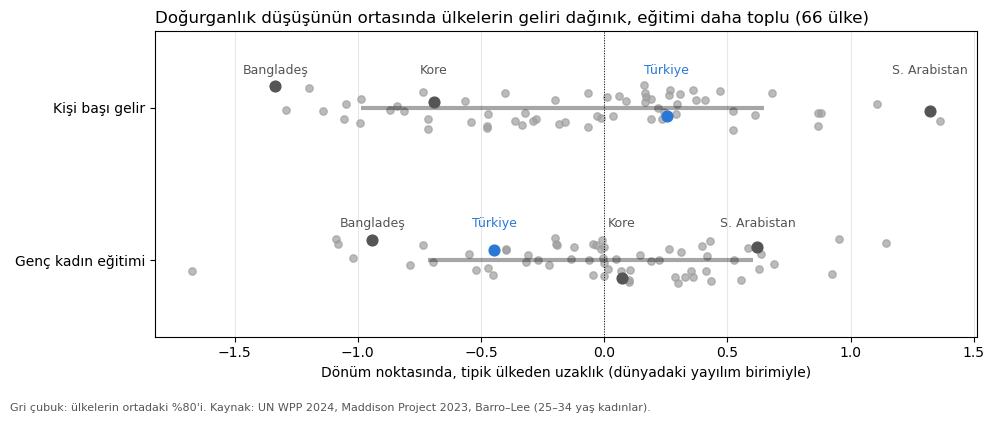

In [8]:
orn["z_gelir"] = [(lg - orn["log_gelir"].median()) / G.loc[y].std() for lg, y in zip(orn["log_gelir"], orn["yil"])]
orn["z_egitim"] = [(le - orn["log_egitim"].median()) / E.loc[y].std() for le, y in zip(orn["log_egitim"], orn["yil"])]

etiket = {"Türkiye": "#2a78d6", "Bangladesh": "#555555", "Saudi Arabia": "#555555", "Republic of Korea": "#555555"}
kisa = {"Türkiye": "Türkiye", "Bangladesh": "Bangladeş", "Saudi Arabia": "S. Arabistan", "Republic of Korea": "Kore"}
fig, ax = plt.subplots(figsize=(10, 4))
rng = np.random.default_rng(1)
for satir, (sutun, ad) in enumerate([("z_egitim", "Genç kadın eğitimi"), ("z_gelir", "Kişi başı gelir")]):
    yk = satir + rng.uniform(-0.15, 0.15, len(orn))
    ax.scatter(orn[sutun], yk, s=28, color="#9e9e9e", alpha=0.7)
    for ulke, r in etiket.items():
        i = orn.index[orn["Location"] == ulke]
        if len(i):
            ax.scatter(orn.loc[i, sutun], yk[orn.index.get_loc(i[0])], s=60, color=r, zorder=3)
            ax.annotate(kisa[ulke], (orn.loc[i[0], sutun], satir + 0.22), ha="center", color=r, fontsize=9)
    ax.hlines(satir, orn[sutun].quantile(0.1), orn[sutun].quantile(0.9), color="black", lw=3, alpha=0.35)
ax.axvline(0, color="black", lw=0.7, ls=":")
ax.set_yticks([0, 1], ["Genç kadın eğitimi", "Kişi başı gelir"])
ax.set_xlabel("Dönüm noktasında, tipik ülkeden uzaklık (dünyadaki yayılım birimiyle)")
ax.set_ylim(-0.5, 1.5); ax.grid(axis="x", alpha=0.3)
ax.set_title(f"Doğurganlık düşüşünün ortasında ülkelerin geliri dağınık, eğitimi daha toplu ({len(orn)} ülke)", loc="left")
plt.figtext(0.01, -0.04, "Gri çubuk: ülkelerin ortadaki %80'i. Kaynak: UN WPP 2024, Maddison Project 2023, Barro–Lee (25–34 yaş kadınlar).", fontsize=8, color="#555")
plt.tight_layout(); plt.savefig("../outputs/05_para_mi_okul_mu.png", dpi=150, bbox_inches="tight"); plt.show()

## 9. Kayıt

In [9]:
orn[["LocID", "ISO3_code", "Location", "bolge", "pop2023", "t0", "gelir", "egitim",
     "hata_gelir", "hata_egitim", "hata_takvim"]].to_csv("../clean/para_okul_tablosu.csv", index=False)
print("Kaydedildi: clean/para_okul_tablosu.csv,", len(orn), "ülke")

Kaydedildi: clean/para_okul_tablosu.csv, 66 ülke


## 🟡 Sorular (cevapları bana yaz)

1. **4. bölüm:** "Gelir 22 kat, eğitim 7 kat farklı" demek neden adil değil? Kendi cümlelerinle anlat.
2. **5. bölüm:** Takvim kıyası neden bu analizin en önemli parçası? Bu kıyas olmasaydı hangi yanlış sonuca varırdık?
3. **2. bölüm:** Hangi bölgeler analizde neredeyse hiç yok? Bu, sonucumuzu nasıl sınırlıyor?